# Part 8: what could be done, as planning arithmetic

The models in Parts 1 to 6 are **prediction** models: they say what is likely to happen (units likely to be lost, households likely to need housing) and where. They do not say which **action** works or what it costs: the data contain no costs and no
policy variation to estimate that. This part uses the predictions for planning arithmetic only (`src/actions.py`), in three steps, each conditional on stated assumptions:

1. **Targeting.** If preservation effort could be aimed at properties, which rule covers the most expected loss per property acted on?
2. **Capacity.** How does the units-at-stake figure compare with what LIHTC produces today?
3. **Levers.** What combinations of preservation and new production hold the affordable-unit ratio at its 2023 level?

Nothing here is a forecast of what policy will do, and "covered" or "preserved" always means "if the action succeeds".

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import actions as A
from viz import apply_style, SERIES, save_figure, SURFACE, MUTED, BASELINE, INK_2, dot, SEQUENTIAL

apply_style()
pd.set_option("display.width", 220)
panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
abbr = panel.groupby("state_fips").state_abbr.first()

## 1. Targeting: units against likelihood

The rescue model (Part 5) scores the HOME-only and HUD-program properties whose last subsidy ends in 2026 to 2035 (11,327 properties, 41 percent of the expiring units; LIHTC and RHS are not scored). A property's expected unrescued units are its units times the chance that
it is not rescued if the subsidy lapses (an upper bound, as in Part 5). Two natural rules give different answers because the properties most likely to be lost are not the ones holding the most units.

In [2]:
s = A.scored_properties()
bands = A.size_bands(s)
display(bands.round(3))
tt = A.targeting_table(s)
display(tt.round(3))
bands.to_csv("outputs/tables/targeting_by_size.csv"); tt.to_csv("outputs/tables/targeting_rules.csv", index=False)
print(f"{len(s)} scored properties, {s.units_ub.sum():,.0f} units, {s.unrescued_ub.sum():,.0f} expected unrescued")
small = bands.loc[["1-10", "11-25"]]
print(f"properties of 25 units or fewer are {small.share_properties.sum():.0%} of properties but {small.share_units.sum():.0%} of units and {small.share_unrescued.sum():.0%} of the expected unrescued units; "
      f"properties of 51 to 200 units hold {bands.loc[['51-100', '101-200']].share_unrescued.sum():.0%} of the expected unrescued units")

,properties,units,rescue_chance,unrescued,share_properties,share_units,share_unrescued,unrescued_per_property
band,,,,,,,,
1-10,5110,19840,0.006,19640.687,0.451,0.049,0.056,3.844
11-25,1902,32726,0.027,31765.340,0.168,0.081,0.090,16.701
26-50,1736,68257,0.057,64237.696,0.153,0.168,0.182,37.003
51-100,1569,115013,0.097,103445.347,0.139,0.283,0.293,65.931
101-200,824,112062,0.160,93568.054,0.073,0.276,0.265,113.553
200+,186,58356,0.272,40054.260,0.016,0.144,0.114,215.345


,rule,share of unrescued units covered,properties to act on,share of scored properties
0,largest first,0.25,548,0.048
1,largest first,0.50,1539,0.136
2,largest first,0.80,3672,0.324
3,lowest rescue chance first,0.25,8042,0.710
4,lowest rescue chance first,0.50,9753,0.861
5,lowest rescue chance first,0.80,10920,0.964
6,random,0.25,2832,0.250
7,random,0.50,5664,0.500
8,random,0.80,9062,0.800


11327 scored properties, 406,254 units, 352,711 expected unrescued
properties of 25 units or fewer are 62% of properties but 13% of units and 15% of the expected unrescued units; properties of 51 to 200 units hold 56% of the expected unrescued units


C:\Users\erick\AppData\Local\Temp\ipykernel_23836\3390925773.py:15: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


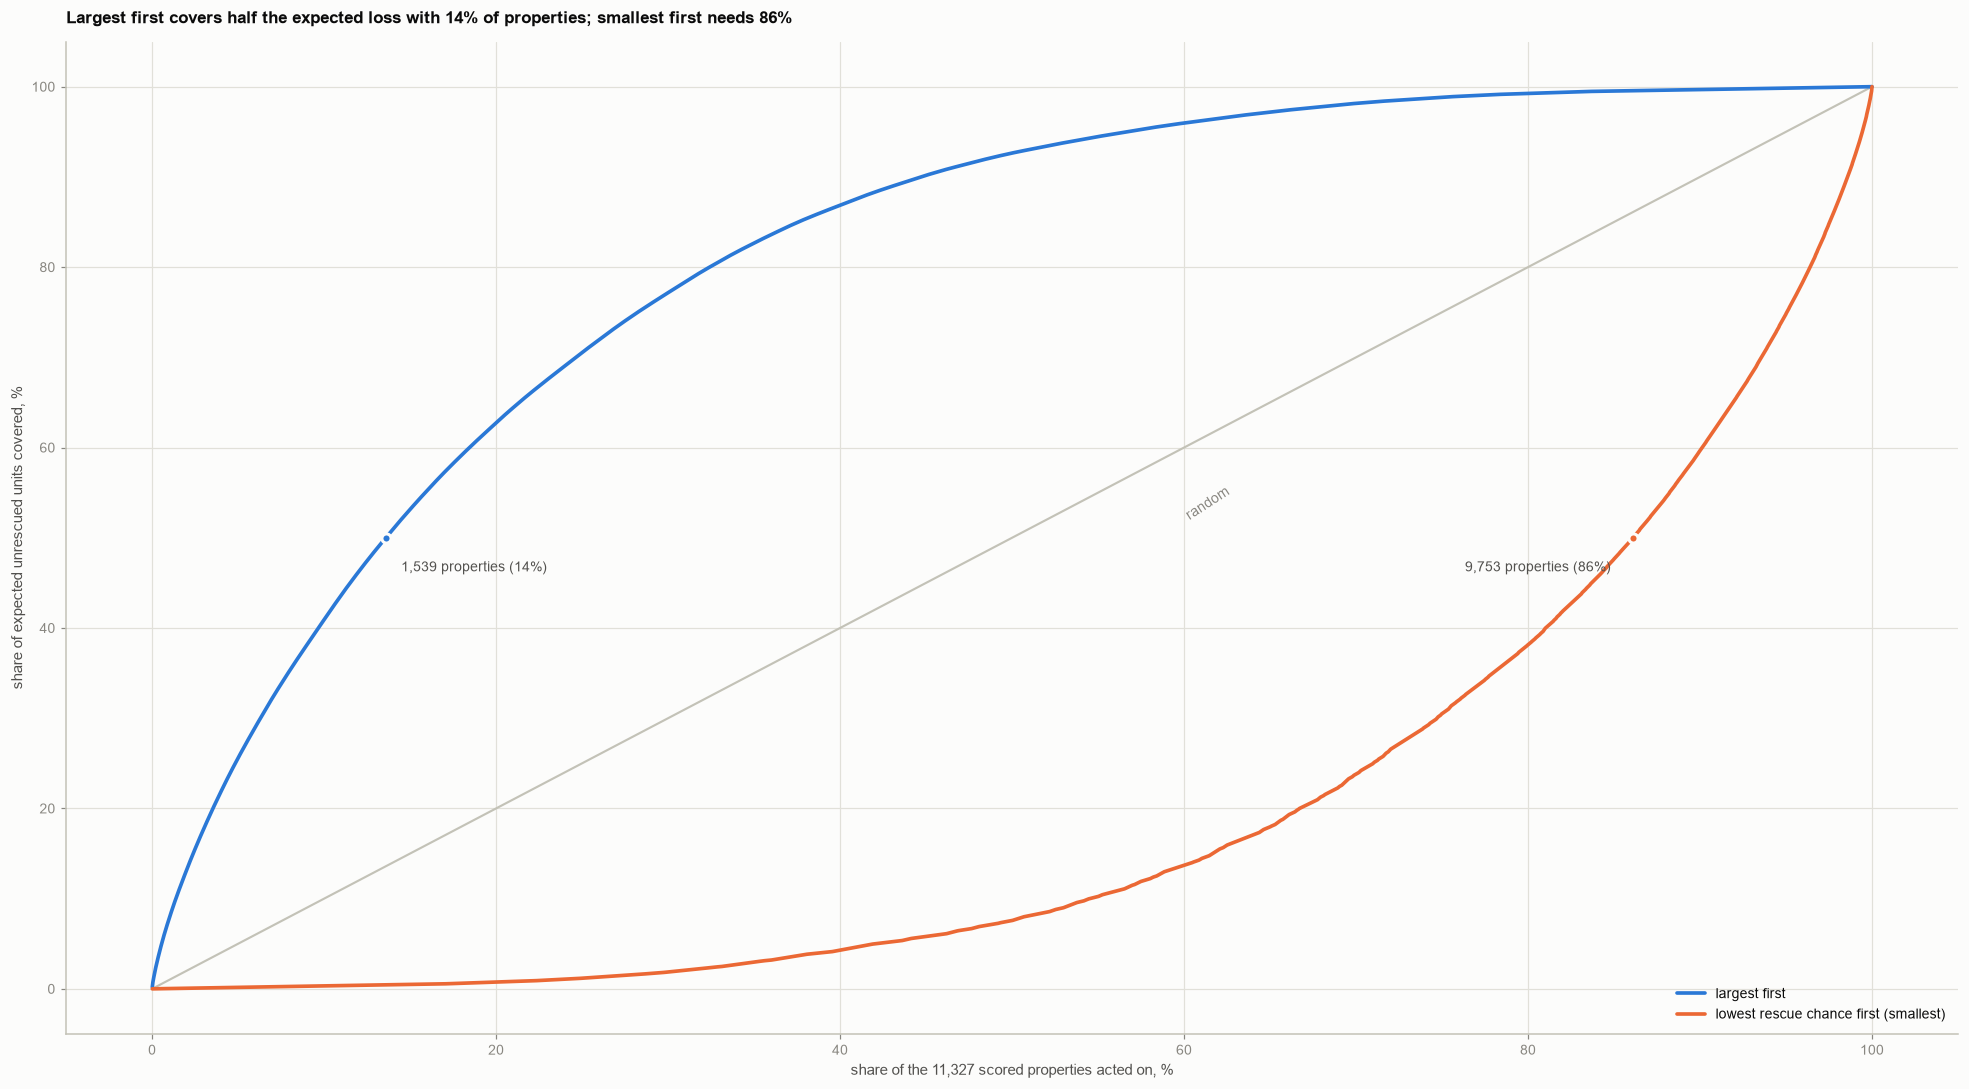

C:\Users\erick\AppData\Local\Temp\ipykernel_23836\3390925773.py:27: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


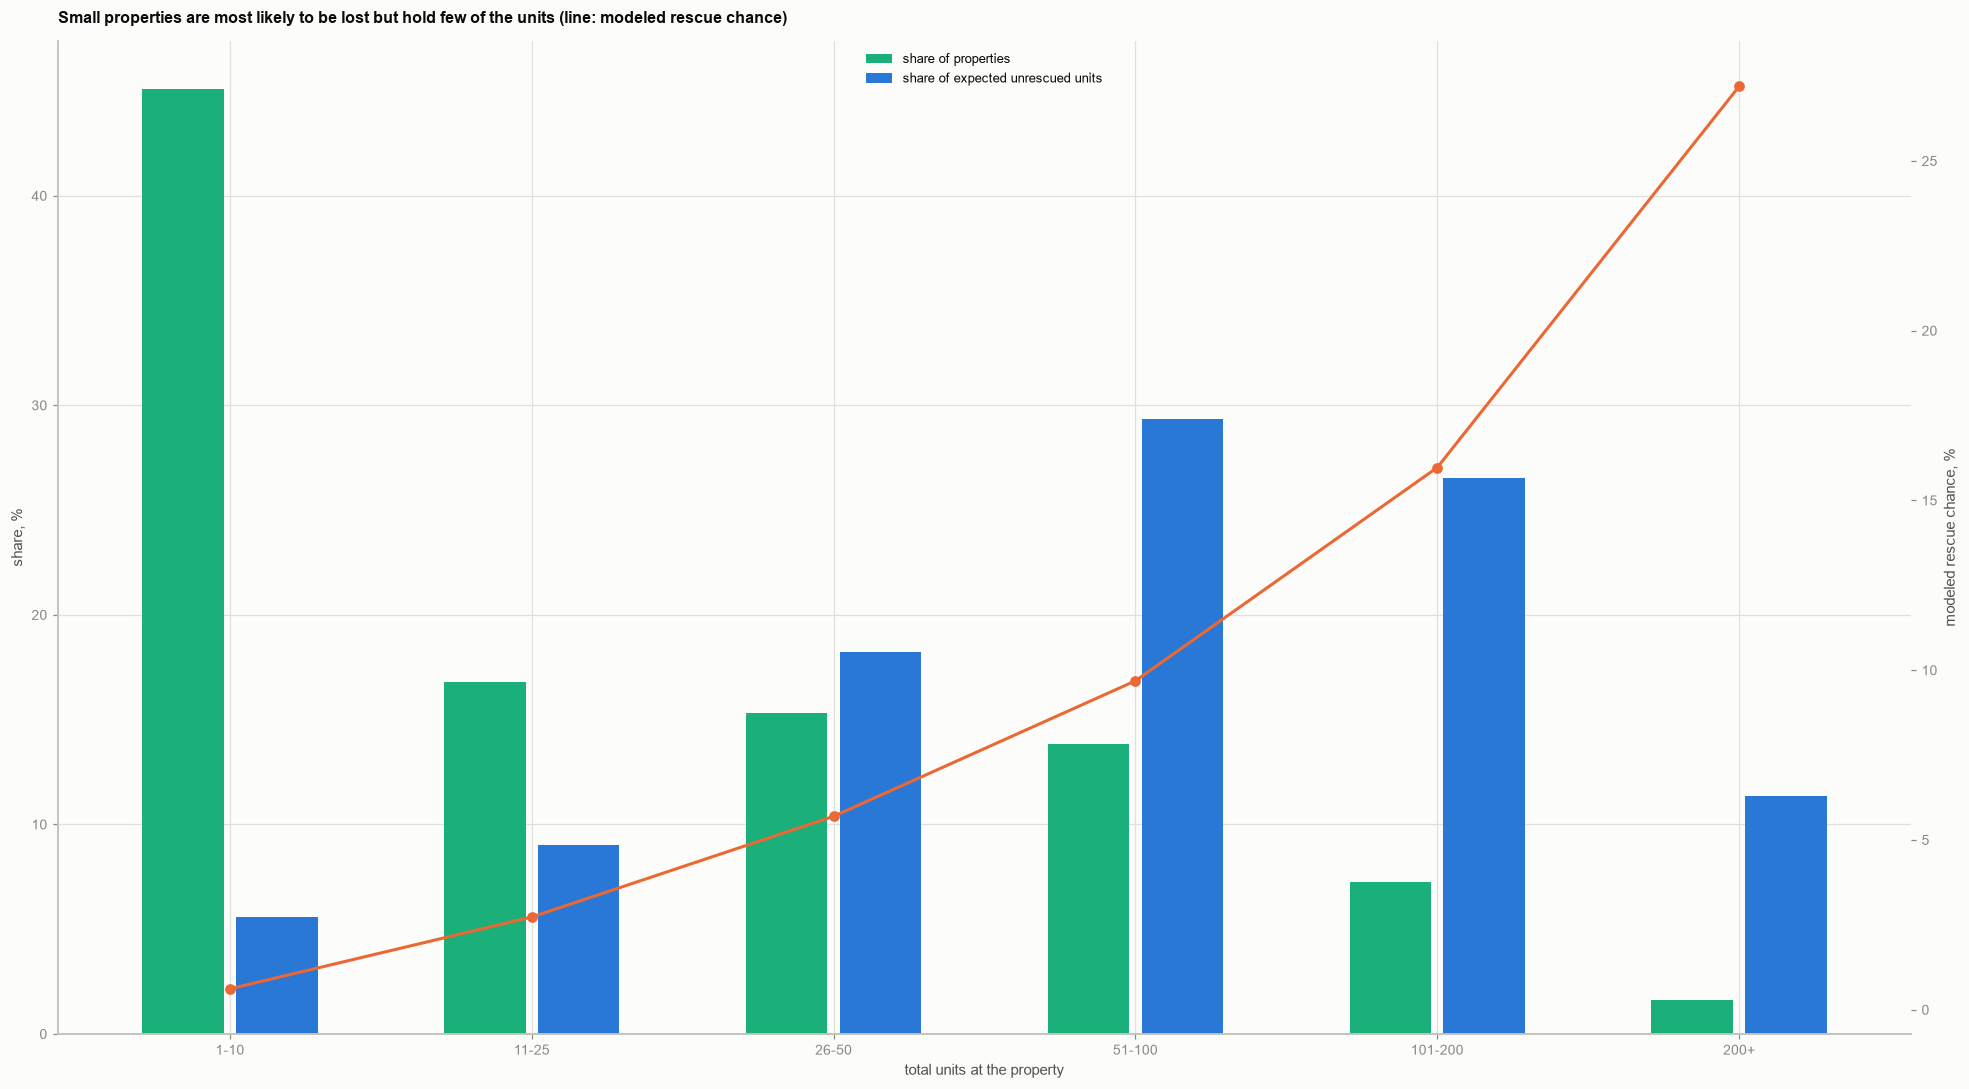

In [3]:
cl = A.coverage_curve(s, s.unrescued_ub); cs = A.coverage_curve(s, -s.p_rescue)
fig, ax = plt.subplots(figsize=(18, 10))
ax.plot([0, 100], [0, 100], color=BASELINE, lw=1.4, zorder=1)
ax.plot(100 * cl.share_properties, 100 * cl.share_covered, color=SERIES[0], lw=2.4, label="largest first")
ax.plot(100 * cs.share_properties, 100 * cs.share_covered, color=SERIES[1], lw=2.4, label="lowest rescue chance first (smallest)")
ax.text(60, 52, "random", color=MUTED, fontsize=9, rotation=33)
n50l, f50l = A.properties_for_share(cl, 0.5); n50s, f50s = A.properties_for_share(cs, 0.5)
for f, c in ((f50l, SERIES[0]), (f50s, SERIES[1])):
    dot(ax, 100 * f, 50, c)
ax.annotate(f"{n50l:,} properties ({f50l:.0%})", (100 * f50l, 50), xytext=(10, -22), textcoords="offset points", fontsize=9, color=INK_2)
ax.annotate(f"{n50s:,} properties ({f50s:.0%})", (100 * f50s, 50), xytext=(-110, -22), textcoords="offset points", fontsize=9, color=INK_2)
ax.set_xlabel("share of the 11,327 scored properties acted on, %"); ax.set_ylabel("share of expected unrescued units covered, %")
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Largest first covers half the expected loss with {f50l:.0%} of properties; smallest first needs {f50s:.0%}", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "81_targeting_curves", part="08_actions")
plt.show()

fig, ax = plt.subplots(figsize=(18, 10))
x = np.arange(len(bands)); w = 0.27
for k, (col, lab, c) in enumerate((("share_properties", "share of properties", SERIES[2]), ("share_unrescued", "share of expected unrescued units", SERIES[0]))):
    ax.bar(x + (k - 0.5) * w * 1.15, 100 * bands[col], width=w, color=c, label=lab)
ax2 = ax.twinx(); ax2.plot(x, 100 * bands.rescue_chance, color=SERIES[1], marker="o", lw=2); ax2.set_ylabel("modeled rescue chance, %", color=INK_2); ax2.grid(False)
ax.set_xticks(x, bands.index); ax.set_xlabel("total units at the property"); ax.set_ylabel("share, %")
ax.legend(frameon=False, loc="upper center", fontsize=8.5)
ax.set_title("Small properties are most likely to be lost but hold few of the units (line: modeled rescue chance)", fontsize=10.5, loc="left")
fig.tight_layout()
save_figure(fig, "81_size_bands", part="08_actions")
plt.show()

## 2. Capacity: the stake against current LIHTC output

Units at stake by 2035 (Part 6, midpoint) per year over 2023 to 2035, against the units LIHTC placed in service per year in 2015 to 2019 (the last years the database reports completely). Not all LIHTC output is net new (some is rehabilitation and
resyndication), so this is a comparison of scale, not a statement of how much could be built.

In [4]:
stake = pd.read_csv("outputs/tables/units_at_stake_state.csv", dtype={"state_fips": str})
cap = A.capacity_by_state(stake)
cap.to_csv("outputs/tables/capacity_by_state.csv", index=False)
nat_stake_low, nat_stake_high = stake.stake_low.sum() / A.HORIZON_YEARS, stake.stake_high.sum() / A.HORIZON_YEARS
nat_lihtc = cap.lihtc_per_year.sum()
print(f"national: stake {nat_stake_low:,.0f} to {nat_stake_high:,.0f} units a year over {A.HORIZON_YEARS} years, against {nat_lihtc:,.0f} LIHTC units placed a year in 2015 to 2019: {nat_stake_low / nat_lihtc:.0%} to {nat_stake_high / nat_lihtc:.0%}")
print(f"states where the stake equals more than {A.HORIZON_YEARS} years of the state's own LIHTC output: {int((cap.years_of_lihtc_needed > A.HORIZON_YEARS).sum())} of 51; median {cap.years_of_lihtc_needed.median():.1f} years")
display(cap.sort_values("years_of_lihtc_needed", ascending=False).head(8)[["state", "stake_mid", "lihtc_per_year", "years_of_lihtc_needed"]].round(1).reset_index(drop=True))
display(cap.sort_values("years_of_lihtc_needed").head(5)[["state", "stake_mid", "lihtc_per_year", "years_of_lihtc_needed"]].round(1).reset_index(drop=True))

national: stake 74,987 to 86,081 units a year over 12 years, against 104,581 LIHTC units placed a year in 2015 to 2019: 72% to 82%
states where the stake equals more than 12 years of the state's own LIHTC output: 24 of 51; median 11.7 years


,state,stake_mid,lihtc_per_year,years_of_lihtc_needed
0,AL,19656.2,480.0,41.0
1,SD,5506.1,206.8,26.6
2,ID,9202.6,349.8,26.3
3,IL,25208.2,971.6,25.9
4,OK,14380.8,594.8,24.2
5,NE,8036.2,345.6,23.3
6,WI,23058.6,1155.6,20.0
7,CT,11629.6,597.2,19.5


,state,stake_mid,lihtc_per_year,years_of_lihtc_needed
0,WA,19510.8,5610.0,3.5
1,NY,42497.9,11865.2,3.6
2,CA,42295.1,10835.2,3.9
3,MN,17921.3,3190.0,5.6
4,DC,6071.9,1054.6,5.8


C:\Users\erick\AppData\Local\Temp\ipykernel_23836\1799236903.py:11: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


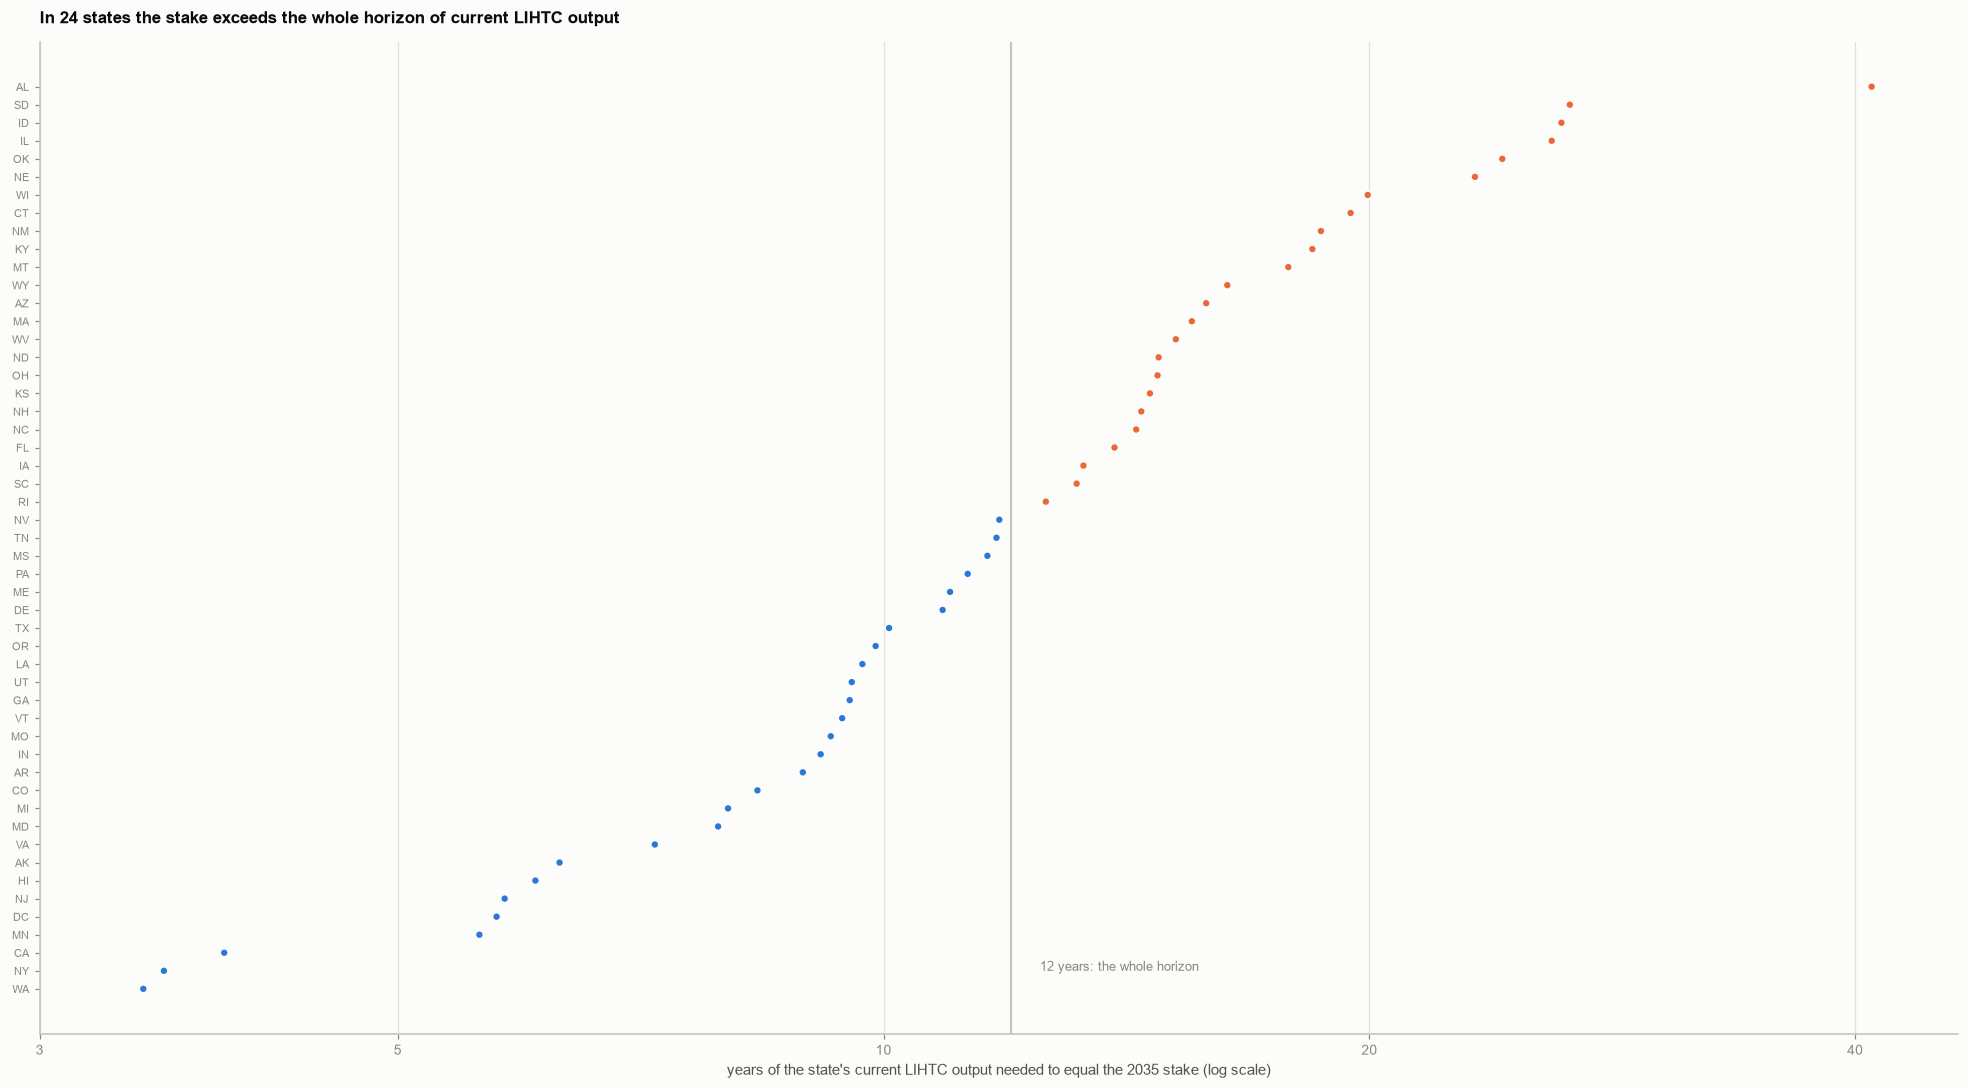

In [5]:
c = cap.sort_values("years_of_lihtc_needed").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(18, 10))
ys = np.arange(len(c))
cols = [SERIES[1] if v > A.HORIZON_YEARS else SERIES[0] for v in c.years_of_lihtc_needed]
ax.scatter(c.years_of_lihtc_needed, ys, s=30, color=cols, edgecolor=SURFACE, linewidth=1.3, zorder=3)
ax.axvline(A.HORIZON_YEARS, color=BASELINE, lw=1.4); ax.text(A.HORIZON_YEARS + 0.5, 1, f"{A.HORIZON_YEARS} years: the whole horizon", fontsize=8.5, color=MUTED)
ax.set_xscale("log"); ax.set_xticks([3, 5, 10, 20, 40]); ax.set_xticklabels(["3", "5", "10", "20", "40"]); ax.minorticks_off()
ax.set_yticks(ys, c.state, fontsize=7.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("years of the state's current LIHTC output needed to equal the 2035 stake (log scale)")
ax.set_title(f"In {int((cap.years_of_lihtc_needed > A.HORIZON_YEARS).sum())} states the stake exceeds the whole horizon of current LIHTC output", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "81_capacity_by_state", part="08_actions")
plt.show()

## 3. Levers: holding the affordable-unit ratio

Affordable units per 100 ELI renters was 53.6 in 2023 (5.85 million rent-affordable units, CHAS 2018-2022, for 10.92 million ELI renters). With the baseline demand scenario (11.57 million ELI renters in 2035) and **no action** the ratio falls to 50.6 even if nothing is lost; if the preservation
pieces of Part 6 (0.56 to 0.69 million units) came out of the stock in full, it falls to about 45. That is an upper bound on deterioration, because some subsidized units that leave a program stay rent-affordable. The grid shows the 2035 ratio for combinations of the share of those losses
that is prevented and new units added per year (2023 to 2035), at the midpoint loss.

In [6]:
sc = pd.read_csv("outputs/tables/scenarios_state.csv", dtype={"state_fips": str})
b = sc[sc.scenario == "baseline"]
stock = b[b.year == 2023].afford_units.sum(); e23 = b[b.year == 2023].eli_renters.sum(); e35 = b[b.year == 2035].eli_renters.sum()
loss_lo = stake.nhpd_unrescued_lb.sum() + stake.lihtc_leaving_adj.sum() + stake.mortgage_lb.sum()
loss_hi = stake.nhpd_unrescued_ub.sum() + stake.lihtc_leaving.sum() + stake.mortgage_ub.sum()
ratio23 = 100 * stock / e23
print(f"2023 ratio {ratio23:.1f}; 2035 with no losses and no action {100 * stock / e35:.1f}; with losses {100 * (stock - loss_hi) / e35:.1f} to {100 * (stock - loss_lo) / e35:.1f} (losses {loss_lo:,.0f} to {loss_hi:,.0f})")
grid = A.lever_grid(stock, e35, (loss_lo + loss_hi) / 2)
display(grid.round(1))
grid.to_csv("outputs/tables/lever_grid.csv")
need_lo, need_hi = 0.01 * ratio23 * e35 - stock + loss_lo, 0.01 * ratio23 * e35 - stock + loss_hi
print(f"units that must be preserved or added by 2035 to hold the 2023 ratio: {need_lo:,.0f} to {need_hi:,.0f} ({need_lo / A.HORIZON_YEARS:,.0f} to {need_hi / A.HORIZON_YEARS:,.0f} a year); "
      f"with nothing preserved that is {need_lo / A.HORIZON_YEARS / nat_lihtc:.0%} to {need_hi / A.HORIZON_YEARS / nat_lihtc:.0%} of current LIHTC output; growth alone accounts for {0.01 * ratio23 * (e35 - e23):,.0f}")

2023 ratio 53.6; 2035 with no losses and no action 50.6; with losses 44.6 to 45.7 (losses 558,401 to 691,531)


,0k per year,25k per year,50k per year,75k per year,100k per year
0% preserved,45.2,47.8,50.4,52.9,55.5
25% preserved,46.5,49.1,51.7,54.3,56.9
50% preserved,47.9,50.5,53.1,55.6,58.2
75% preserved,49.2,51.8,54.4,57.0,59.6
100% preserved,50.6,53.2,55.8,58.3,60.9


units that must be preserved or added by 2035 to hold the 2023 ratio: 907,074 to 1,040,204 (75,590 to 86,684 a year); with nothing preserved that is 72% to 83% of current LIHTC output; growth alone accounts for 348,673


C:\Users\erick\AppData\Local\Temp\ipykernel_23836\4018669550.py:12: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


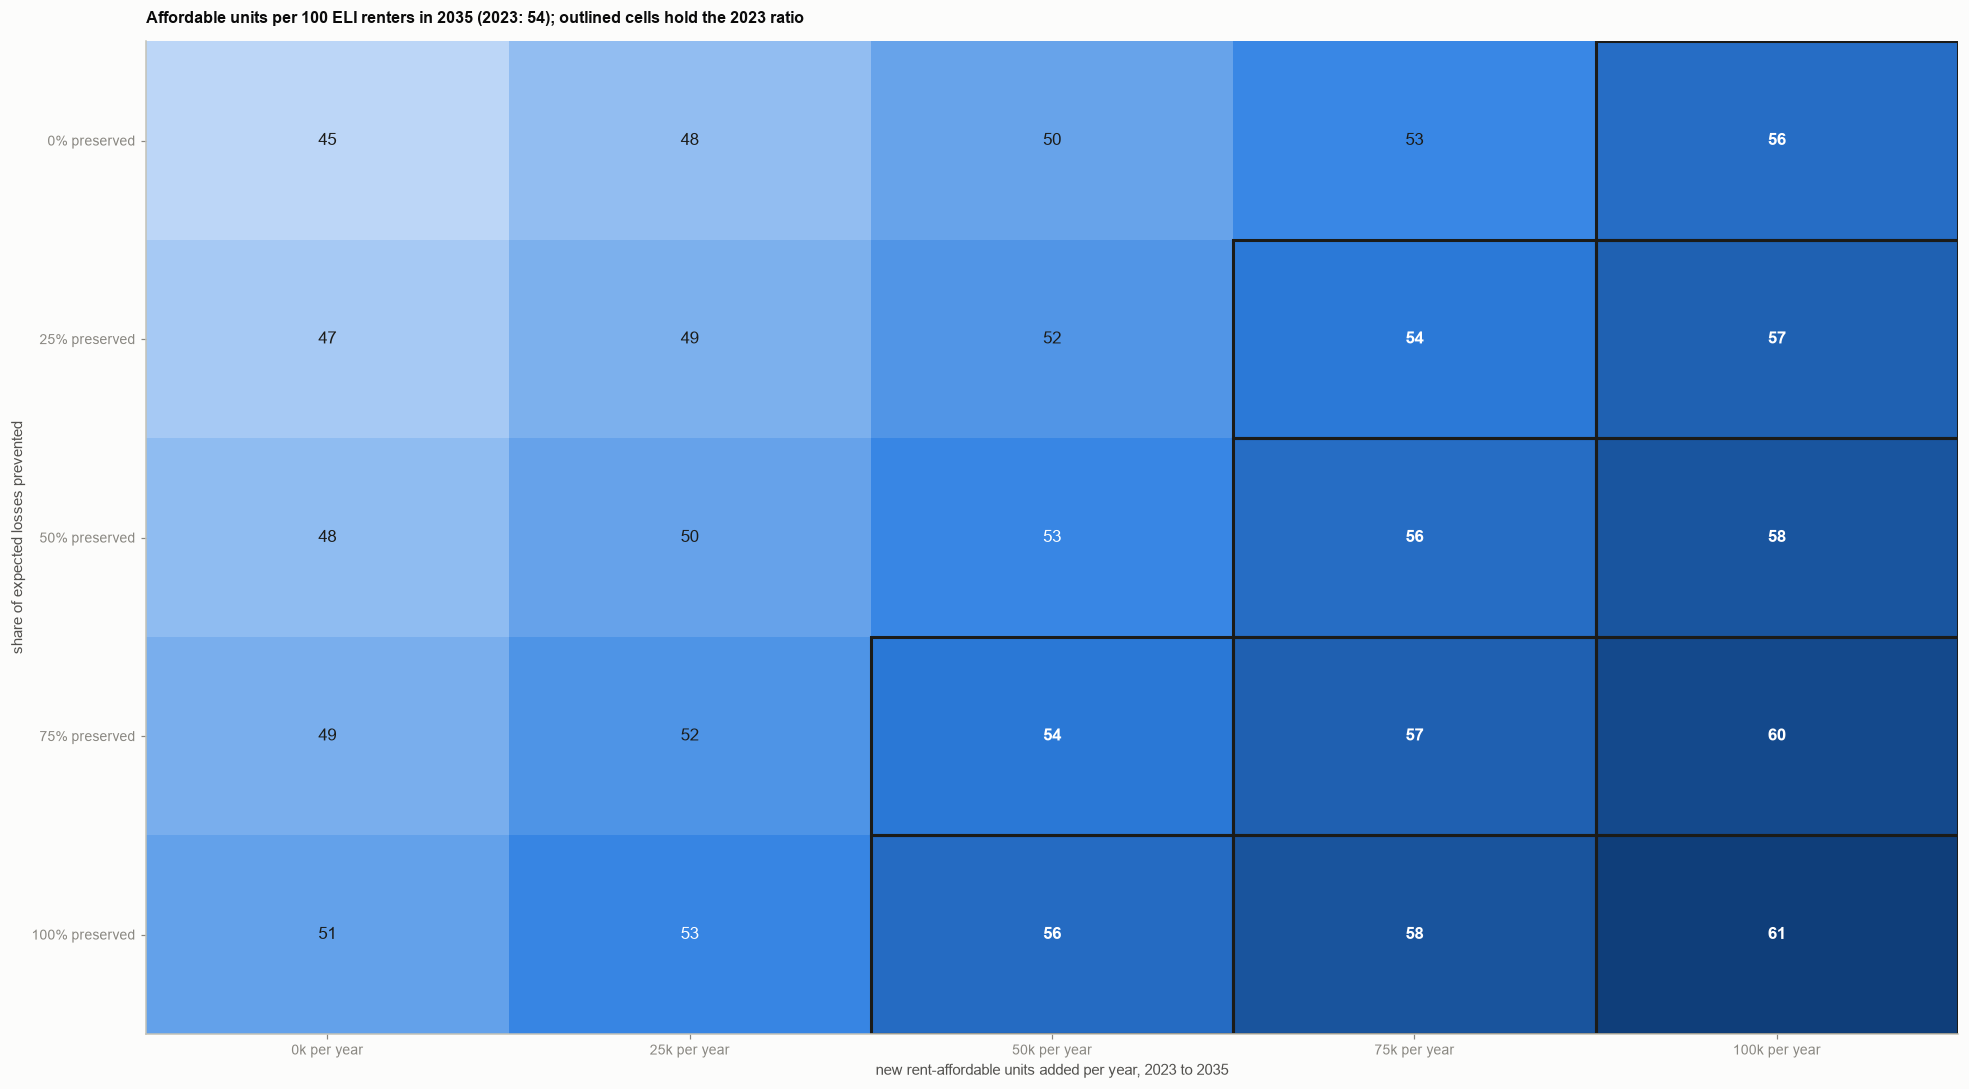

In [7]:
fig, ax = plt.subplots(figsize=(18, 10))
im = ax.imshow(grid.values, cmap=SEQUENTIAL, aspect="auto", vmin=44, vmax=62)
ax.set_xticks(range(grid.shape[1]), grid.columns); ax.set_yticks(range(grid.shape[0]), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=11, color="#ffffff" if v > 53 else "#1b1b18", fontweight="bold" if v >= ratio23 else "normal")
        if v >= ratio23:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="#1b1b18", lw=2))
ax.grid(False); ax.set_xlabel("new rent-affordable units added per year, 2023 to 2035"); ax.set_ylabel("share of expected losses prevented")
ax.set_title(f"Affordable units per 100 ELI renters in 2035 (2023: {ratio23:.0f}); outlined cells hold the 2023 ratio", fontsize=10.5, loc="left")
fig.tight_layout()
save_figure(fig, "81_lever_grid", part="08_actions")
plt.show()

## Findings

**Prediction versus prescription.** The models in Parts 1 to 6 are prediction models (what is likely to happen, where, and how big). This part adds planning arithmetic on top of them. It still does not say which action works or what it costs; every figure below is conditional on the stated assumptions.

**Targeting corrects an earlier recommendation.** Parts 5 and the reports said preservation should aim at small properties, because their modeled rescue chance is lowest (0.6 percent at 1 to 10 units, 2.7 at 11 to 25, 5.7 at 26 to 50, 9.7 at 51 to 100, 16 at 101 to 200, 27 at 200 or more). That is right if the aim is the properties most likely to be lost,
and wrong if the aim is the most units per action. Of the 11,327 scored properties (406,000 units; 353,000 expected unrescued), those of 25 units or fewer are **62 percent of the properties but 13 percent of the units and 15 percent of the expected unrescued units**, while properties of 51 to 200 units are 21 percent of the properties and **56 percent** of the unrescued
units, despite rescue chances of 10 to 16 percent. To cover half of the expected unrescued units takes **1,539 properties (14 percent) if the largest go first, 5,664 (50 percent) at random, and 9,753 (86 percent) if the smallest go first**; for 80 percent the numbers are 3,672 (32 percent), 9,062 (80 percent), and 10,920 (96 percent). So where each action
carries a fixed cost, the units-efficient rule is largest first, and small properties are the right target only for other aims the data do not measure (neighborhood spread, mission). This covers the scored HOME-only and HUD-program properties (41 percent of expiring units); for LIHTC the unit of action is the state (Part 5b), and RHS is unscored.

**Capacity.** The stake of 0.90 to 1.03 million units over 2023 to 2035 is 75,000 to 86,000 units a year, **72 to 82 percent of the 104,581 units LIHTC placed in service per year in 2015 to 2019**. In **24 of 51 states** the stake equals more than 12 years of the state's own LIHTC output (median 11.7 years). The most stretched are Alabama (41 years), South Dakota (27), Idaho (26),
Illinois (26), and Oklahoma (24); the least are Washington (3.5), New York (3.6), California (3.9), Minnesota (5.6), and DC (5.8). This is a comparison of scale: not all LIHTC output is net new, and recent state-level reporting can be incomplete (Alabama's 480 units a year looks low), so the state ranking is indicative.

**Levers.** The ratio of rent-affordable units to ELI renters is 53.6 in 2023. With baseline demand and no losses it falls to 50.6 by 2035; with the preservation losses of Part 6 taken out of the stock in full (an upper bound) it falls to 44.6 to 45.7. Holding 53.6 requires preserving or adding **0.91 to 1.04 million units by 2035 (76,000 to 87,000 a year)**, of which
about 0.35 million is the growth in ELI renters. In the grid, each additional 25,000 units added a year is worth about 2.6 points of the ratio and each 25 percent of expected losses prevented about 1.3 points. Combinations that hold the ratio include: no preservation and about 81,000 units a year; 25 percent of losses prevented and 75,000 a year; 75 percent prevented and 50,000 a year; all losses prevented
and about 29,000 a year. 50 percent prevented with 50,000 a year falls just short (53.1).

**What this cannot say.** Costs: there are no cost data, so no lever is ranked by cost-effectiveness. Effectiveness: preserving a property is assumed to succeed. The ratio counts rent-affordable units, not units that are affordable and available, and subsidized units that leave a program may stay rent-affordable, so deterioration is an upper bound. LIHTC output is treated as if it were net new. The stake pieces
overlap and carry the limits of Parts 4 to 6. To estimate what an intervention achieves, the project would need cost data and variation in policy (for example state preservation set-asides) that it does not have. Tables: `outputs/tables/targeting_by_size.csv`, `targeting_rules.csv`, `capacity_by_state.csv`, `lever_grid.csv`.